# Exercice 1 : opérations de base

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [16]:
img = cv2.imread("imagesCLR.jpeg", cv2.IMREAD_COLOR)

In [17]:
hauteur, largeur, canaux = img.shape

In [18]:
print("Hauteur : ", hauteur)
print("largeur : ", largeur)
print("Les canaux : ", canaux)
print("Type : ", img.dtype)

Hauteur :  678
largeur :  452
Les canaux :  3
Type :  uint8


In [19]:
B = img[:, :, 0]
G = img[:, :, 1]
R = img[:, :, 2]


In [20]:
print("Canal Bleu :", B.shape)
print("Canal Vert :", G.shape)
print("Canal Rouge :", R.shape)

Canal Bleu : (678, 452)
Canal Vert : (678, 452)
Canal Rouge : (678, 452)


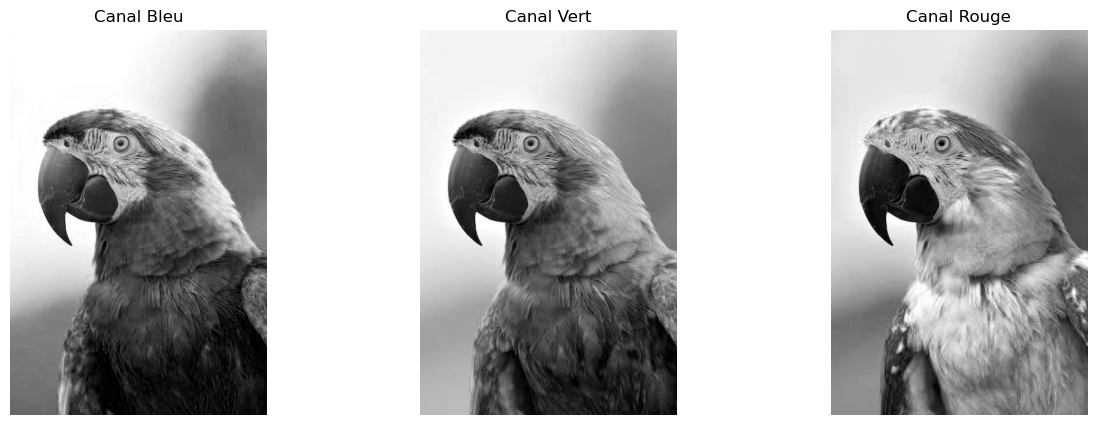

In [23]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(B, cmap="gray")
plt.title("Canal Bleu")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(G, cmap="gray")
plt.title("Canal Vert")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(R, cmap="gray")
plt.title("Canal Rouge")
plt.axis("off")

plt.show()

In [24]:
gray_img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

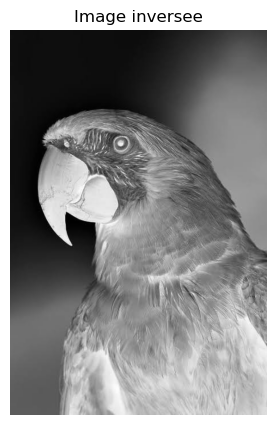

In [41]:
inverted_img = 255 - gray_img

plt.figure(figsize=(6, 5))
plt.imshow(cv2.cvtColor(inverted_img, cv2.COLOR_BGR2RGB))
plt.title("Image inversee")
plt.axis("off")
plt.show()

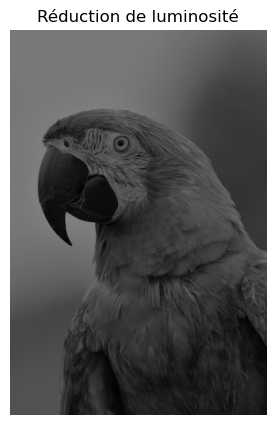

In [ ]:
dark_img = gray_img / 2
dark_img = dark_img.astype(np.uint8)

plt.figure(figsize=(6, 5))
plt.imshow(cv2.cvtColor(dark_img, cv2.COLOR_BGR2RGB))
plt.title("Réduction de luminosite")
plt.axis("off")
plt.show()

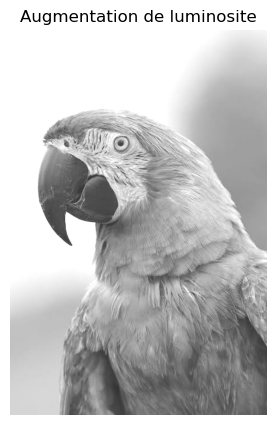

In [36]:
bright_img = np.clip(gray_img.astype(np.int16) + 50, 0, 255)
bright_img = bright_img.astype(np.uint8)

plt.figure(figsize=(6, 5))
plt.imshow(cv2.cvtColor(bright_img, cv2.COLOR_BGR2RGB))
plt.title("Augmentation de luminosite")
plt.axis("off")
plt.show()

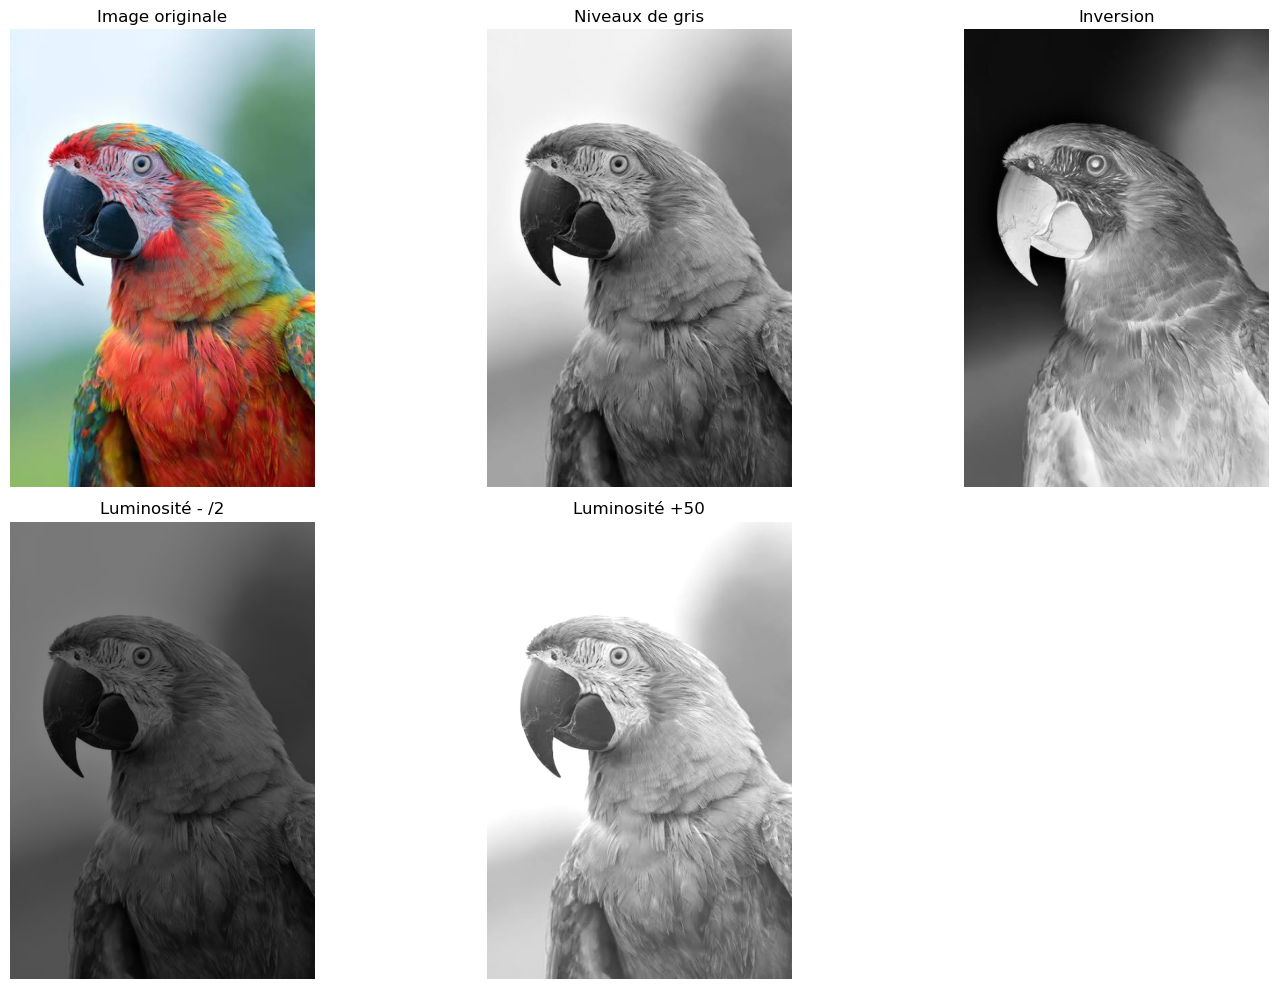

In [42]:
plt.figure(figsize=(15, 10))

# Image originale
plt.subplot(2, 3, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Image originale")
plt.axis("off")

# Niveaux de gris
plt.subplot(2, 3, 2)
plt.imshow(gray_img, cmap="gray")
plt.title("Niveaux de gris")
plt.axis("off")

# Inversion
plt.subplot(2, 3, 3)
plt.imshow(cv2.cvtColor(inverted_img, cv2.COLOR_BGR2RGB))
plt.title("Inversion")
plt.axis("off")

# Réduction luminosité
plt.subplot(2, 3, 4)
plt.imshow(cv2.cvtColor(dark_img, cv2.COLOR_BGR2RGB))
plt.title("Luminosité - /2")
plt.axis("off")

# Augmentation luminosité
plt.subplot(2, 3, 5)
plt.imshow(cv2.cvtColor(bright_img, cv2.COLOR_BGR2RGB))
plt.title("Luminosité +50")
plt.axis("off")

plt.tight_layout()
plt.show()

## Réponses aux questions

### 1. Que remarquez-vous lorsque vous affichez séparément les canaux R, G et B ?

Chaque canal représente l’intensité d’une seule couleur. Les zones claires correspondent à une forte présence de cette couleur, tandis que les zones sombres correspondent à une faible présence.

### 2. Quelle est la différence entre l’inversion et la réduction de luminosité ?

L’inversion remplace chaque valeur par `255 - valeur`, ce qui crée un effet de négatif et modifie les couleurs.

La réduction de luminosité diminue simplement les valeurs des pixels, par exemple en les divisant par 2, ce qui rend l’image plus sombre sans inverser les couleurs.

### 3. Pourquoi doit-on saturer les valeurs à 255 lors d’une addition ?

Une image `uint8` ne peut contenir que des valeurs entre **0 et 255**. Lorsqu’on ajoute une valeur, certains pixels peuvent dépasser 255.

On limite donc les valeurs à **255** pour éviter un dépassement et conserver une image correcte.

# Exercice 2 : Histogramme

In [45]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [73]:
img = cv2.imread("images.jpeg", cv2.IMREAD_GRAYSCALE)

In [74]:
hist = cv2.calcHist([img], [0], None, [256], [0, 256])

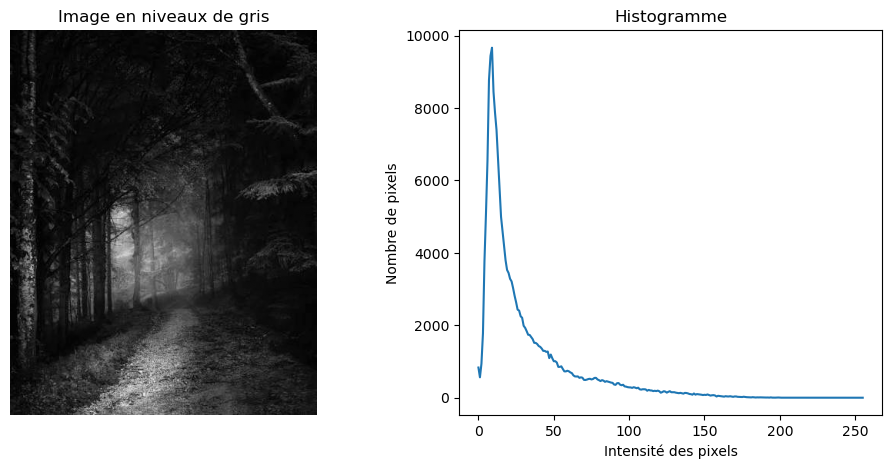

In [75]:
# Afficher l'image et l'histogramme
plt.figure(figsize=(12, 5))

# Image
plt.subplot(1, 2, 1)
plt.imshow(img, cmap="gray")
plt.title("Image en niveaux de gris")
plt.axis("off")

# Histogramme
plt.subplot(1, 2, 2)
plt.plot(hist)
plt.title("Histogramme")
plt.xlabel("Intensité des pixels")
plt.ylabel("Nombre de pixels")

plt.show()

## Réponses

L’image est sombre, car la majorité des pixels se trouve dans les faibles intensités, donc vers la gauche de l’histogramme.

La dynamique est plutôt faible si les pixels sont concentrés dans une petite partie de l’histogramme. Cela signifie que l’image utilise principalement des niveaux de gris faibles.

# Exercice 3 : Étirement de l’histogramme

In [89]:
etir_img = cv2.imread("images.jpeg", cv2.IMREAD_GRAYSCALE)

In [90]:
I_min, I_max = np.min(etir_img), np.max(etir_img)

In [91]:
stretched_img = ((etir_img - I_min) / (I_max - I_min) * 255).astype(np.uint8)

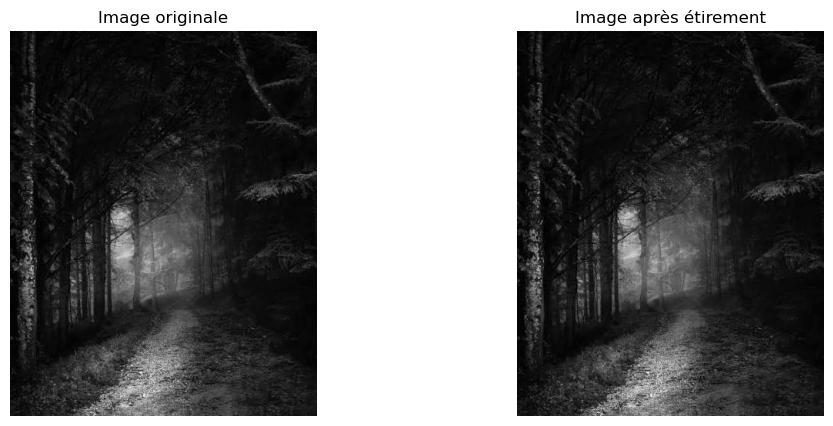

In [92]:
plt.figure(figsize=(12, 5))

# Image originale
plt.subplot(1, 2, 1)
plt.imshow(etir_img, cmap="gray")
plt.title("Image originale")
plt.axis("off")

# Image étirée
plt.subplot(1, 2, 2)
plt.imshow(stretched_img, cmap="gray")
plt.title("Image après étirement")
plt.axis("off")

plt.show()

In [93]:
print("Min :", gray.min())
print("Max :", gray.max())

Min : 0
Max : 223


## Réponses aux questions
Après l’étirement, l’histogramme est plus étalé entre 0 et 255.

Les niveaux de gris sont mieux répartis, ce qui permet généralement d’améliorer le contraste de l’image.

- **Efficace :** lorsque les intensités sont concentrées dans une petite plage de valeurs.
- **Inutile :** lorsque l’image utilise déjà presque toute la plage 0–255.

# Exercice 4 : Égalisation

In [94]:
egal_img = cv2.imread("images.jpeg", cv2.IMREAD_GRAYSCALE)

In [95]:
equalized = cv2.equalizeHist(egal_img)

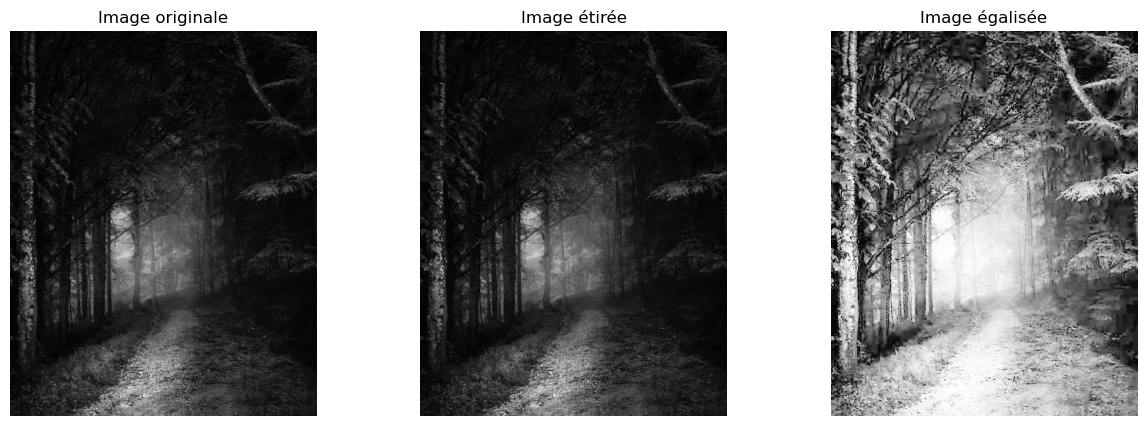

In [96]:
plt.figure(figsize=(15, 5))

# Image originale
plt.subplot(1, 3, 1)
plt.imshow(img, cmap="gray")
plt.title("Image originale")
plt.axis("off")

# Image étirée
plt.subplot(1, 3, 2)
plt.imshow(etir_img, cmap="gray")
plt.title("Image étirée")
plt.axis("off")

# Image égalisée
plt.subplot(1, 3, 3)
plt.imshow(equalized, cmap="gray")
plt.title("Image égalisée")
plt.axis("off")

plt.show()

/tmp/ipykernel_14167/2021618214.py:5: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.10; the parameter will become keyword-only in 3.12.
  plt.hist(gray.ravel(), 256, [0, 256])
/tmp/ipykernel_14167/2021618214.py:10: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.10; the parameter will become keyword-only in 3.12.
  plt.hist(stretched.ravel(), 256, [0, 256])
/tmp/ipykernel_14167/2021618214.py:15: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.10; the parameter will become keyword-only in 3.12.
  plt.hist(equalized.ravel(), 256, [0, 256])


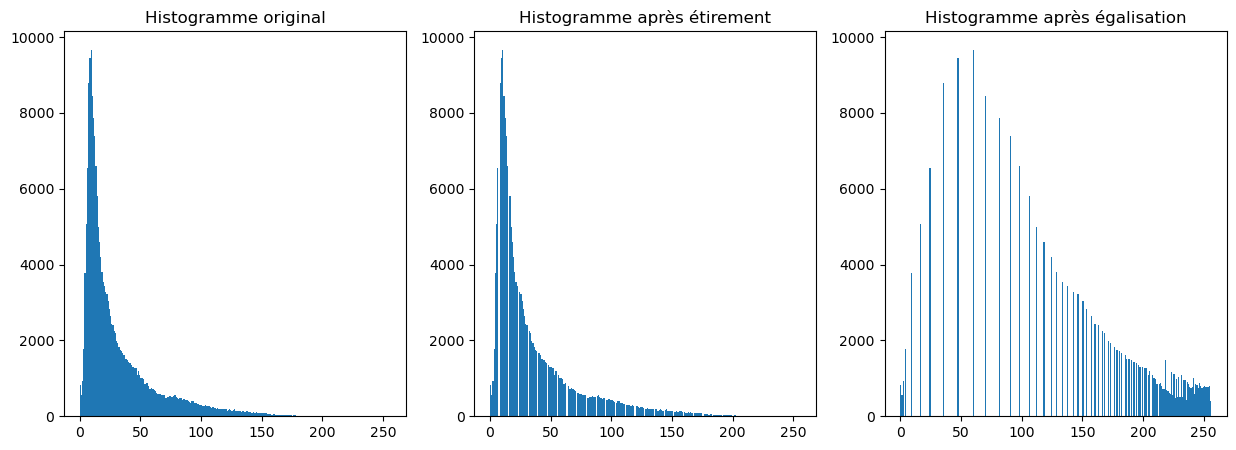

In [97]:
plt.figure(figsize=(15, 5))

# Original
plt.subplot(1, 3, 1)
plt.hist(gray.ravel(), 256, [0, 256])
plt.title("Histogramme original")

# Étirement
plt.subplot(1, 3, 2)
plt.hist(stretched.ravel(), 256, [0, 256])
plt.title("Histogramme après étirement")

# Égalisation
plt.subplot(1, 3, 3)
plt.hist(equalized.ravel(), 256, [0, 256])
plt.title("Histogramme après égalisation")

plt.show()

### Réponses

**1. L’histogramme est-il plus uniforme ?**

Oui, l’égalisation répartit mieux les niveaux de gris sur la plage 0–255. 
L’histogramme devient généralement plus réparti, mais pas forcément parfaitement uniforme.

**2. Avantages / inconvénients par rapport à l’étirement ?**

- **Avantage :** l’égalisation peut améliorer davantage le contraste lorsque les niveaux de gris sont mal répartis.
- **Inconvénient :** elle peut amplifier le bruit et produire une image avec un contraste trop fort.

L’étirement est plus simple et conserve généralement mieux l’apparence naturelle de l’image.

# Exercice 5 : CLAHE

In [ ]:
clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

clahe_image = clahe.apply(img)

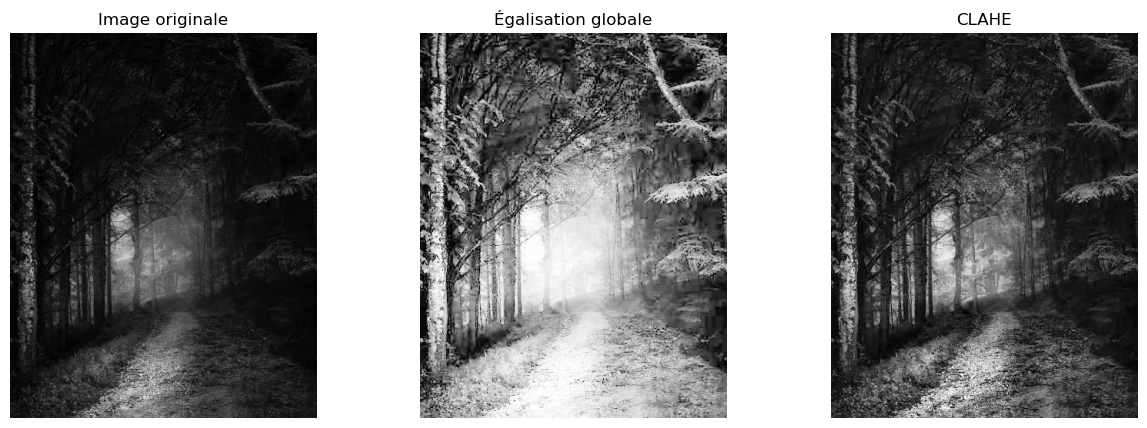

In [100]:
plt.figure(figsize=(15, 5))

# Image originale
plt.subplot(1, 3, 1)
plt.imshow(img, cmap="gray")
plt.title("Image originale")
plt.axis("off")

# Égalisation globale
plt.subplot(1, 3, 2)
plt.imshow(equalized, cmap="gray")
plt.title("Égalisation globale")
plt.axis("off")

# CLAHE
plt.subplot(1, 3, 3)
plt.imshow(clahe_image, cmap="gray")
plt.title("CLAHE")
plt.axis("off")

plt.show()

### Réponses

**1. Pourquoi CLAHE évite la surexposition ?**

CLAHE travaille localement sur des petites zones et limite l’augmentation du contraste avec `clipLimit`. Il évite donc qu’une zone devienne trop claire.

**2. Dans quels contextes est-il plus adapté ?**

CLAHE est adapté aux images où le contraste n’est pas uniforme, par exemple lorsqu’une partie de l’image est sombre et une autre claire. Il permet de mieux faire apparaître les détails locaux tout en limitant l’amplification du bruit.

# Exercice 6 : Cas des images couleur

In [104]:
image_c = cv2.imread("imagesCLR.jpeg")

B, G, R = cv2.split(image_c)

/tmp/ipykernel_14167/2106920097.py:4: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.10; the parameter will become keyword-only in 3.12.
  plt.hist(R.ravel(), 256, [0, 256])
/tmp/ipykernel_14167/2106920097.py:8: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.10; the parameter will become keyword-only in 3.12.
  plt.hist(G.ravel(), 256, [0, 256])
/tmp/ipykernel_14167/2106920097.py:12: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.10; the parameter will become keyword-only in 3.12.
  plt.hist(B.ravel(), 256, [0, 256])


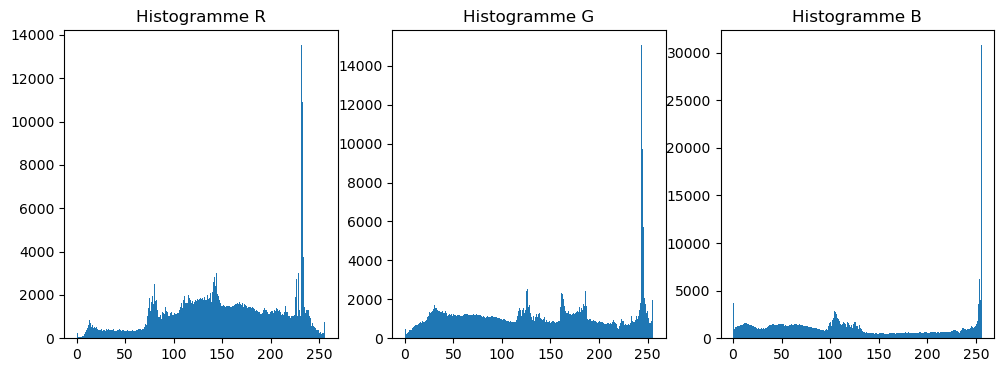

In [105]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.hist(R.ravel(), 256, [0, 256])
plt.title("Histogramme R")

plt.subplot(1, 3, 2)
plt.hist(G.ravel(), 256, [0, 256])
plt.title("Histogramme G")

plt.subplot(1, 3, 3)
plt.hist(B.ravel(), 256, [0, 256])
plt.title("Histogramme B")

plt.show()

In [106]:
R_eq = cv2.equalizeHist(R)
G_eq = cv2.equalizeHist(G)
B_eq = cv2.equalizeHist(B)

image_eq = cv2.merge([B_eq, G_eq, R_eq])

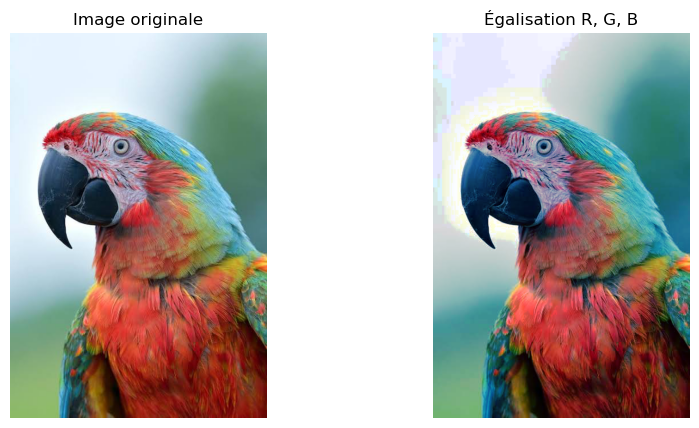

In [108]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image_c, cv2.COLOR_BGR2RGB))
plt.title("Image originale")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(image_eq, cv2.COLOR_BGR2RGB))
plt.title("Égalisation R, G, B")
plt.axis("off")

plt.show()

In [109]:
# Conversion BGR → Lab
lab = cv2.cvtColor(image_c, cv2.COLOR_BGR2LAB)

# Séparer les canaux
L, a, b = cv2.split(lab)

# Créer CLAHE
clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

# Appliquer CLAHE uniquement sur L
L_clahe = clahe.apply(L)

# Recombiner
lab_clahe = cv2.merge([L_clahe, a, b])

# Retour vers BGR
image_lab = cv2.cvtColor(lab_clahe, cv2.COLOR_LAB2BGR)

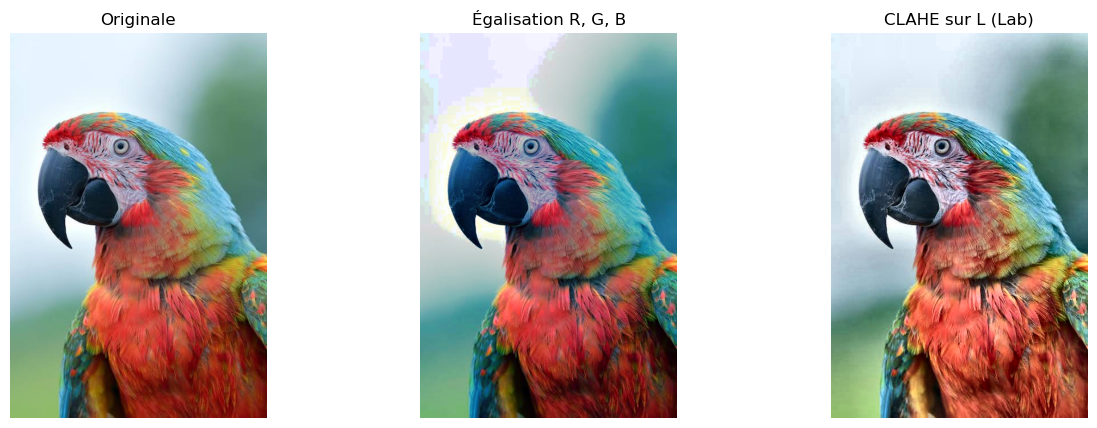

In [110]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(image_c, cv2.COLOR_BGR2RGB))
plt.title("Originale")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(cv2.cvtColor(image_eq, cv2.COLOR_BGR2RGB))
plt.title("Égalisation R, G, B")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(image_lab, cv2.COLOR_BGR2RGB))
plt.title("CLAHE sur L (Lab)")
plt.axis("off")

plt.show()

### Réponses

**1. Quelle méthode conserve le mieux les couleurs ?**

La méthode **Lab + CLAHE sur le canal L** conserve mieux les couleurs.

**2. Pourquoi travailler sur la luminance et non sur R, G, B ?**

Les canaux R, G et B contiennent des informations de couleur et de luminosité. 
Les modifier séparément peut changer les couleurs de l’image.

Dans l’espace Lab, le canal L représente la luminosité. On peut donc améliorer le contraste sur L uniquement, tout en gardant les couleurs `a` et `b` presque inchangées.

# Exercice 7 : Comparaison finale

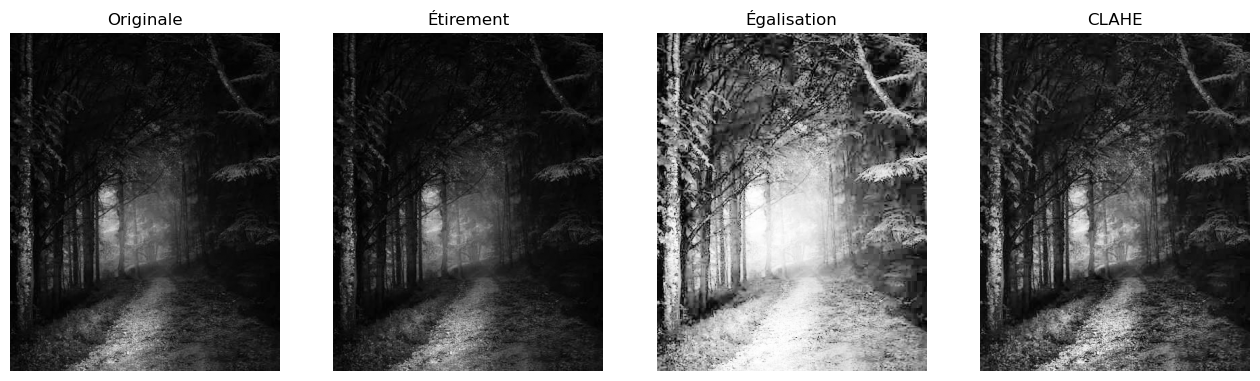

In [111]:
plt.figure(figsize=(16, 5))

plt.subplot(1, 4, 1)
plt.imshow(img, cmap="gray")
plt.title("Originale")
plt.axis("off")

plt.subplot(1, 4, 2)
plt.imshow(etir_img, cmap="gray")
plt.title("Étirement")
plt.axis("off")

plt.subplot(1, 4, 3)
plt.imshow(equalized, cmap="gray")
plt.title("Égalisation")
plt.axis("off")

plt.subplot(1, 4, 4)
plt.imshow(clahe_image, cmap="gray")
plt.title("CLAHE")
plt.axis("off")

plt.show()

/tmp/ipykernel_14167/1216981057.py:4: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.10; the parameter will become keyword-only in 3.12.
  plt.hist(img.ravel(), 256, [0, 256])
/tmp/ipykernel_14167/1216981057.py:8: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.10; the parameter will become keyword-only in 3.12.
  plt.hist(etir_img.ravel(), 256, [0, 256])
/tmp/ipykernel_14167/1216981057.py:12: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.10; the parameter will become keyword-only in 3.12.
  plt.hist(equalized.ravel(), 256, [0, 256])
/tmp/ipykernel_14167/1216981057.py:16: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.10; the parameter will become keyword-only in 3.12.
  plt.hist(clahe_image.ravel(), 256, [0, 256])


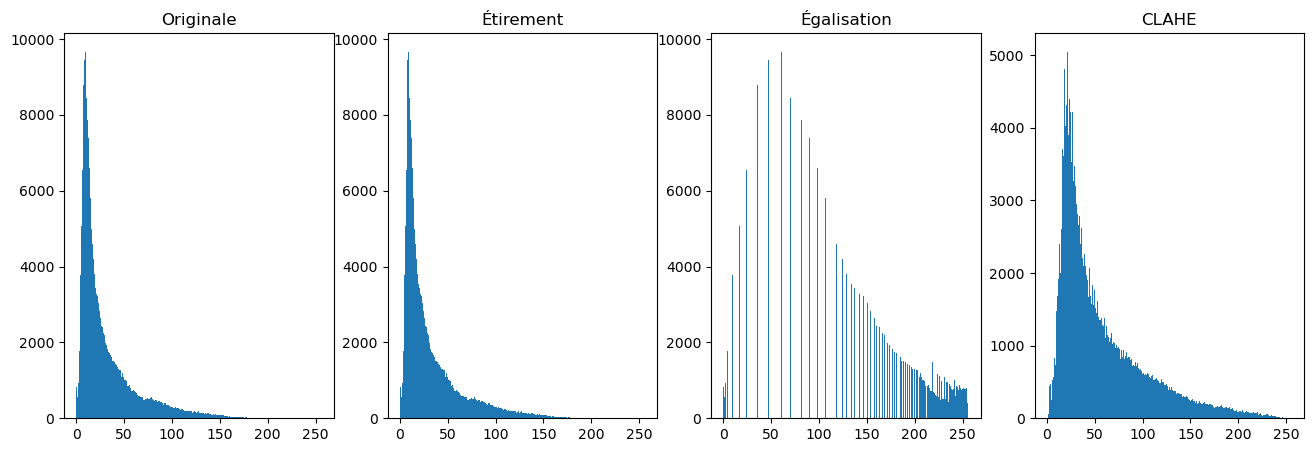

In [112]:
plt.figure(figsize=(16, 5))

plt.subplot(1, 4, 1)
plt.hist(img.ravel(), 256, [0, 256])
plt.title("Originale")

plt.subplot(1, 4, 2)
plt.hist(etir_img.ravel(), 256, [0, 256])
plt.title("Étirement")

plt.subplot(1, 4, 3)
plt.hist(equalized.ravel(), 256, [0, 256])
plt.title("Égalisation")

plt.subplot(1, 4, 4)
plt.hist(clahe_image.ravel(), 256, [0, 256])
plt.title("CLAHE")

plt.show()

## Discussion finale

**1. Quelle méthode est la plus efficace pour une image sombre ?**

L’étirement est efficace lorsque l’image utilise une petite plage de niveaux de gris.
L’égalisation améliore le contraste global.
CLAHE est particulièrement efficace lorsque les détails importants se trouvent dans différentes zones de l’image.

**2. Quelle méthode est la plus adaptée pour une image médicale ou satellite ?**

CLAHE est souvent bien adaptée aux images médicales et satellites car elle améliore le contraste localement et permet de mieux faire ressortir les détails sans modifier fortement toute l’image.

**3. Que se passe-t-il si on applique ces techniques directement sur une image couleur en RGB ?**

Si on applique l’étirement ou l’égalisation séparément sur les canaux **R, G et B**, les couleurs peuvent être modifiées.

Chaque canal est traité indépendamment, ce qui peut créer un déséquilibre entre les trois couleurs et produire des couleurs artificielles.

Il est donc préférable de travailler sur la **luminance** de l’image, par exemple avec l’espace **Lab**, afin d’améliorer le contraste tout en conservant mieux les couleurs.